# Proyecto : Predicción de entregas tardías en DataCo

**Integrante:** Diego Andres Fernandez Gonzalez


Este notebook es **el proyecto del equipo**. Se llena por partes, una sección en cada clase, y al final es la base de la sustentación.

| Sección | Se trabaja en | Fase de CRISP-DM |
|---|---|---|
| 0. Configuración | 26 de octubre | |
| 1. El problema | 26 de octubre | 1. Comprensión del negocio |
| 2. Los datos | 26 de octubre | 2. Comprensión de los datos |
| 3. Limpieza | 27 de octubre | 3. Preparación de los datos |
| 4. Análisis exploratorio (EDA) | 27 de octubre | 2 y 3 |
| 5. Modelo | 28 de octubre | 4. Modelado y 5. Evaluación |
| 6. Conclusiones | 11 de noviembre | 5. Evaluación y 6. Despliegue |

**Cómo usar la plantilla**

- Las celdas y tablas marcadas con **COMPLETAR** son las que el equipo debe cambiar.
- Las celdas que dicen **Su código aquí** son espacios libres: ahí el equipo explora a su manera, con las preguntas y los consejos de cada sección como guía.
- Las demás celdas ya funcionan: léanlas, ejecútenlas y entiendan qué hacen. Pueden modificarlas si su caso lo necesita.
- Ejecuten el notebook **de arriba hacia abajo**. Antes de cada commit, usen *Restart Kernel and Run All* para comprobar que corre completo.
- Al terminar cada sesión: `git pull`, `git add notebooks/proyecto_equipo.ipynb`, `git commit -m "feat: ..."` y `git push`.

## 0. Configuración

**COMPLETAR una sola vez.** Estas cinco variables son lo único que necesita el resto del notebook para funcionar con su dataset.

- `ARCHIVO`: ruta al CSV, **relativa a la carpeta `notebooks/`**. Por eso empieza con `../`, que significa "subir una carpeta".
- `SEPARADOR`: el carácter que separa las columnas. Casi siempre es `","`; los archivos de datos.gov.co suelen usar `";"`.
- `OBJETIVO`: el nombre exacto de la columna que quieren predecir o explicar (la variable objetivo o *target*).
- `TIPO_PROBLEMA`: `"regresion"` si el objetivo es un número (precio, ventas, días) o `"clasificacion"` si es una categoría (sí/no, tipo de cliente).
- `COLUMNAS_A_EXCLUIR`: columnas que **no** deben usarse para predecir, por ejemplo identificadores o columnas que solo se conocen después del resultado (*data leakage*).

In [1]:
ARCHIVO = "../data/raw/dataco.csv"
SEPARADOR = ","
CODIFICACION = "latin-1" # toca cambiarlo, el csv de dataco no viene en utf-8, sino en latin-1
OBJETIVO = "Late_delivery_risk"  
TIPO_PROBLEMA = "clasificacion"  # "regresion" o "clasificacion"
COLUMNAS_A_EXCLUIR = [
    "Delivery Status",       # dice si el pediddo llegó tarde: es la respuesta
    "Days for shipping (real)", # dias reales
    "shipping date (DateOrders)", # fecha real de envio
]
    

SEMILLA = 42  # fija el azar para que los resultados se repitan

In [2]:
# Librerías. Si alguna falla, instálenla con:  uv add <libreria>
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

assert TIPO_PROBLEMA in ("regresion", "clasificacion"), "TIPO_PROBLEMA debe ser 'regresion' o 'clasificacion'"
print("Configuración lista. Archivo:", ARCHIVO)

Configuración lista. Archivo: ../data/raw/dataco.csv


---
## 1. El problema (26 de octubre)



| Pregunta | Respuesta del equipo |
|---|---|
| ¿Qué **decisión** de negocio se quiere mejorar? | Decidir a tiempo que pedidos se deben priorizar ( acelerar el despacho, cambiar de transportadora o avisarle al cliente) antes de que lleguen tarde. Actualmente el problema se detecta cuando el pedido ya esta retrasado|
| ¿**Quién** toma esa decisión? | El coordinador de logistica o el coordinador de despachos de DataCo |
| ¿Qué **tipo de análisis** es el principal? (descriptivo, diagnóstico, predictivo o prescriptivo) | Es un analisis predictivo. este seria un modelo de clasdificacion que al momento de crear el pedido, hace estimaciones de si llegará tarde. tiene un fuerte apoto en el analisis descriptivo y diasgnostico  |
| ¿Cuál es la **variable objetivo**? |  La variable es 'Late_delivery_risk': 1 si el pedido llegó tarde y 0 si el pedido llegó a tiempo o antes.|
| **Criterio de éxito:** ¿qué métrica y qué umbral indican que el proyecto funcionó? | Este modelo debe detectar al menos el 80 % de los pedidos que realmente llegan tarde en los datos de prueba, y ademas sobrepasan al *baseline*. Eligimos *recall* porque en logistica el error mas caro es que se escape un pedido tardío sin avisarle al cliente.|
| **KPI 1** (SMART: específico, medible, alcanzable, relevante y con periodo) |    Tasa de entregas a tiempo = pedidos entregados a tiempo / total de pedidos enviados. Hoy es del 42,7 %. Meta: llegar al 55 % durante el primer semestre de 2027, medida cada mes. |
| **KPI 2** (SMART) | Porcentaje de pedidos tardios por modo de envios. Meta: reducir un 20 % los retrasos del modo de envio con mas pedidos tardíos durante el primer trimestre de 2027, medido cada mes.|

> **Ejemplo (inmobiliaria):** decisión: fijar el precio de publicación de una casa · quién: el asesor comercial · tipo: predictivo · objetivo: `SalePrice` · éxito: error porcentual medio (MAPE) menor al 15 % · KPI 1: precio mediano por m² por barrio, cada trimestre · KPI 2: días promedio que tarda una casa en venderse, cada mes.

---
## 2. Los datos (26 de octubre)

### 2.1 Cargar y mirar

`pd.read_csv` lee el archivo y lo convierte en un **DataFrame**: una tabla con filas y columnas.

In [3]:
df = pd.read_csv(ARCHIVO, sep=SEPARADOR, encoding=CODIFICACION)

print(f"El dataset tiene {df.shape[0]:,} filas y {df.shape[1]} columnas.")
df.head()

El dataset tiene 180,519 filas y 53 columnas.


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,...,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,...,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,...,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,...,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,...,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,...,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


¿Qué representa **una fila**? (por ejemplo: "una venta de una casa", "un cliente en un mes", "un viaje").

> Respuesta: un producto dentro de un pedido. Un mismo pedido ('Order Id') puede tener varias filas, una por cada producto. Cada fila trae datos del cliente, del producto, del envío y si llegó tarde.

### 2.2 Exploren los datos

**Esta parte es libre.** Añadan las celdas de código que necesiten para el análisis y puedan responder estas preguntas. No hay una única forma correcta de hacerlo.

| Pregunta | Por qué importa |
|---|---|
| ¿Qué tipo tiene cada columna? ¿Alguna columna de números aparece como texto? | Un número leído como texto (`"1.500,00"`, `"$200"`, `"N/A"`) no se puede sumar ni promediar |
| ¿Qué columnas tienen datos faltantes? ¿Cuántos? | Mañana decidirán qué hacer con ellos, y primero hay que saber **por qué** faltan |
| ¿Hay filas repetidas? | Una venta contada dos veces infla los resultados |
| ¿Hay columnas con un valor distinto en cada fila? | Suelen ser identificadores (`id`, cédula): no sirven para predecir |
| ¿Cómo se ve la variable objetivo? | En regresión, ¿hay valores extremos? En clasificación, ¿hay muchos más casos de una clase que de otra? |
| ¿Hay valores imposibles? | Edades negativas, precios en cero, fechas en el futuro |
| ¿Hay columnas que solo se conocen **después** del resultado? | Son *data leakage*: van en `COLUMNAS_A_EXCLUIR` |

**Herramientas útiles** (copien la que necesiten en una celda de código):

```python
df.info()                                   # tipos de cada columna y cuántos valores no nulos tiene
df.describe()                               # resumen de las columnas numéricas: mínimo, máximo, promedio, cuartiles
df.describe(exclude="number")               # resumen de las columnas de texto: valores únicos y el más frecuente
df.isna().sum().sort_values(ascending=False)  # nulos por columna, de mayor a menor
df.isna().mean().mul(100).round(1)          # % de nulos por columna
df.duplicated().sum()                       # cuántas filas repetidas hay
df.nunique()                                # cuántos valores distintos tiene cada columna
df["columna"].value_counts()                # cuántas veces aparece cada categoría
df[OBJETIVO].describe()                     # resumen de la variable objetivo
sns.histplot(df[OBJETIVO])                  # distribución de una variable numérica
sns.countplot(x=df[OBJETIVO])               # casos por clase de una variable categórica
```

**Recomendaciones**

- Una pregunta por celda, y debajo una línea de texto con lo que encontraron. Así el notebook se lee como un informe.
- Tengan a mano el **diccionario de datos** del dataset: muchas dudas ("¿qué significa este código?", "¿por qué está vacío?") se responden ahí.
- Si una salida es muy larga, muestren solo una parte: `.head(10)`.
- Si algo les llama la atención, anótenlo aunque todavía no sepan qué hacer con ello: irá a la tabla de la sección 2.3.

In [4]:
# Tipos de columnas
print(df.dtypes.astype(str).value_counts())

# Columnas con datos faltantes
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(df) * 100).round(2)})

str        24
float64    15
int64      14
Name: count, dtype: int64


,nulos,% nulos
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


Se encuentra que hay 53 columnas entre numeros y texto. Las fechas (`order date (DateOrders)` y `shipping date (DateOrders)`) están guardadas como texto, así que hay que convertirlas. Solo 4 columnas tienen nulos: `Product Description` está 100 % vacía y `Order Zipcode` lo está en un 86 %, así que no aportan. `Customer Lname` y `Customer Zipcode` tienen muy pocos nulos.

In [5]:
print("Filas duplicadas:", df.duplicated().sum())

unicos = df.nunique()
print("Columnas con un solo valor:", list(unicos[unicos == 1].index))
print("Columnas con un valor distinto en cada fila:", list(unicos[unicos == len(df)].index))

# ¿Hay columnas que repiten exactamente la misma información?
pares = [("Customer Id", "Order Customer Id"),
         ("Product Card Id", "Order Item Cardprod Id"),
         ("Category Id", "Product Category Id"),
         ("Product Price", "Order Item Product Price"),
         ("Benefit per order", "Order Profit Per Order"),
         ("Sales per customer", "Order Item Total")]
for a, b in pares:
    print(f"{a} == {b}: {(df[a] == df[b]).mean():.0%}")
    

Filas duplicadas: 0
Columnas con un solo valor: ['Customer Email', 'Customer Password', 'Product Status']
Columnas con un valor distinto en cada fila: ['Order Item Id']
Customer Id == Order Customer Id: 100%
Product Card Id == Order Item Cardprod Id: 100%
Category Id == Product Category Id: 100%
Product Price == Order Item Product Price: 100%
Benefit per order == Order Profit Per Order: 100%
Sales per customer == Order Item Total: 100%


No se encontro filas duplicadas. `Order Item Id` es un identificador (cambia en cada fila). `Customer Email` y `Customer Password` valen siempre `XXXXXXXXX` (están enmascarados) y `Product Status` vale siempre 0, así que no aportan nada. Además, 6 pares de columnas son idénticas (por ejemplo, `Benefit per order` y `Order Profit Per Order`): dejar las dos sería repetir información.

In [6]:
df[["Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street"]].head(3)

,Customer Email,Customer Password,Customer Fname,Customer Lname,Customer Street
0,XXXXXXXXX,XXXXXXXXX,Cally,Holloway,5365 Noble Nectar Island
1,XXXXXXXXX,XXXXXXXXX,Irene,Luna,2679 Rustic Loop
2,XXXXXXXXX,XXXXXXXXX,Gillian,Maldonado,8510 Round Bear Gate


Se encuentra el correo y la contrase;a vienen enmascarsdos (`XXXXXXXXX`), y el nombre, el apellido y la dirección son datos personales. No explican si un pedido llega tarde y no deben usarse en un modelo.

                    pedidos     %
Late_delivery_risk               
0                     81542  45.2
1                     98977  54.8


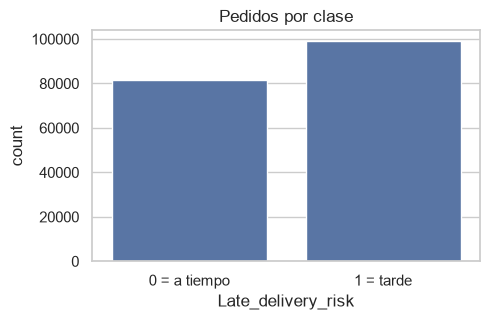

In [7]:
conteo = df[OBJETIVO].value_counts().sort_index()
print(pd.DataFrame({"pedidos": conteo, "%": (conteo / len(df) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(x=df[OBJETIVO], ax=ax)
ax.set_xticks([0, 1], ["0 = a tiempo", "1 = tarde"])
ax.set_title("Pedidos por clase")
plt.show()

Se encuentra que el 54.8 % de las filas son entregas tardias y el 45,2 % no. las clases estan casi balanceadas, pero no un modelo tonto que siempre diga "tarde" ya acertaria el 55 % de las veces

In [8]:
print(pd.crosstab(df["Delivery Status"], df[OBJETIVO]))

coincide = ((df["Days for shipping (real)"] > df["Days for shipment (scheduled)"]).astype(int) == df[OBJETIVO]).mean()
print(f"\nDías reales > días programados coincide con el objetivo en el {coincide:.1%} de las filas")

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0

Días reales > días programados coincide con el objetivo en el 97.5% de las filas


Se encuentra que `Delivery Status` dice "Late delivery" en "todos" los pedidos tardios,  y comparar los días reales con los programados reproduce el objetivo en el **97,5 %** de las filas. Estas columnas solo se conocen después de la entrega: usarlas sería *data leakage* (el modelo haría trampa). Por eso están en `COLUMNAS_A_EXCLUIR`.

In [9]:
pd.crosstab(df["Order Status"], df[OBJETIVO])

Late_delivery_risk,0,1
Order Status,,
CANCELED,3692,0
CLOSED,8507,11109
COMPLETE,25292,34199
ON_HOLD,4354,5450
PAYMENT_REVIEW,811,1082
PENDING,8515,11712
PENDING_PAYMENT,16910,22922
PROCESSING,9399,12503
SUSPECTED_FRAUD,4062,0


Se encuentra que los pedidos `CANCELED` y `SUSPECTED_FRAUD` tienen siempre `Late_delivery_risk = 0` . No es que llegaran a tiempo: nunca se enviaron. Contarlos como "a tiempo" distorsionaría el objetivo.

### 2.3 Problemas de calidad e hipótesis


| # | Problema de calidad encontrado | Columna(s) |
|---|---|---|
| 1 | Pedidos cancelados o sospechosos de fraude que nunca se enviaron, pero aparecen como "no tarde" | `Order Status`  |
| 2 | Columnas vacías, constantes, con datos personales o repetidas  | `Product Description`, `Order Zipcode`, `Product Status`, `Customer Email`, `Benefit per order`…  |
| 3 |  Fechas guardadas como texto | `order date (DateOrders)` |

| # | Hipótesis: ¿qué creemos que explica la variable objetivo? |
|---|---|
| H1 | El modo de envío influye: los modos rápidos (First Class, Second Class) prometen pocos días y por eso se retrasan más.  |
| H2 | El mercado de destino influye: los envíos a regiones lejanas (África, Asia Pacífico) llegan tarde más seguido que los de Estados Unidos y Canadá.  |
| H3 | Las características del pedido (valor, descuento, cantidad) influyen: los pedidos grandes o con descuento se retrasan más.  |

---
## 3. Limpieza (27 de octubre)

Trabajamos sobre una **copia** (`df_limpio`) para no perder los datos originales. Cada decisión se escribe en una celda y se justifica en el registro de abajo.

Antes de rellenar un nulo, pregúntense **por qué falta el dato**:

| Si el dato falta porque... | Decisión típica | Código |
|---|---|---|
| **No existe** (la casa no tiene piscina) | Poner un valor que lo diga | `df_limpio["col"] = df_limpio["col"].fillna("No tiene")` |
| **No se registró** (falla de captura) | Imputar con la mediana (números) o la moda (categorías) | `df_limpio["col"] = df_limpio["col"].fillna(df_limpio["col"].median())` |
| Son **muy pocas filas** con problemas | Eliminar esas filas | `df_limpio = df_limpio.dropna(subset=["col"])` |
| La columna tiene **casi todo vacío** y no aporta | Eliminar la columna | `df_limpio = df_limpio.drop(columns=["col"])` |

Otras operaciones frecuentes:

```python
df_limpio = df_limpio.drop_duplicates()                                  # quitar filas repetidas
df_limpio = df_limpio[df_limpio["precio"] > 0]                            # quitar valores imposibles
df_limpio["fecha"] = pd.to_datetime(df_limpio["fecha"], errors="coerce")  # texto -> fecha
df_limpio["valor"] = pd.to_numeric(df_limpio["valor"].str.replace(",", "."), errors="coerce")  # "1,5" -> 1.5
df_limpio["ciudad"] = df_limpio["ciudad"].str.strip().str.lower()        # unificar textos
```

In [10]:
df_limpio = df.copy()

# Las filas sin variable objetivo no sirven para entrenar ni para evaluar.
df_limpio = df_limpio.dropna(subset=[OBJETIVO])

# Decisión 1: quitar los pedidos que nunca se enviaron (cancelados y sospechosos de fraude)
no_enviados = df_limpio["Order Status"].isin(["CANCELED", "SUSPECTED_FRAUD"])
print(f"Decisión 1: se quitan {no_enviados.sum():,} pedidos no enviados")
df_limpio = df_limpio[~no_enviados]

# Decisión 2: quitar columnas que no aportan o repiten información
columnas_sin_valor = [
    "Product Description", "Order Zipcode", "Product Image", "Product Status",   # vacías, URL o constante
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname",
    "Customer Street",                                                           # datos personales
    "Order Profit Per Order", "Sales per customer", "Order Item Product Price",  # copias de otras columnas
]
df_limpio = df_limpio.drop(columns=columnas_sin_valor)
print(f"Decisión 2: se quitan {len(columnas_sin_valor)} columnas")

# Decisión 3: convertir la fecha del pedido de texto a fecha y sacar variables de calendario
df_limpio["order date (DateOrders)"] = pd.to_datetime(df_limpio["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
df_limpio["anio_pedido"] = df_limpio["order date (DateOrders)"].dt.year
df_limpio["mes_pedido"] = df_limpio["order date (DateOrders)"].dt.month
df_limpio["dia_semana_pedido"] = df_limpio["order date (DateOrders)"].dt.dayofweek  # 0 = lunes
print("Decisión 3: fecha convertida; nuevas columnas anio_pedido, mes_pedido, dia_semana_pedido")

print(f"\nFilas: {len(df):,} antes y {len(df_limpio):,} después")
print(f"Columnas: {df.shape[1]} antes y {df_limpio.shape[1]} después")



Decisión 1: se quitan 7,754 pedidos no enviados
Decisión 2: se quitan 12 columnas
Decisión 3: fecha convertida; nuevas columnas anio_pedido, mes_pedido, dia_semana_pedido

Filas: 180,519 antes y 172,765 después
Columnas: 53 antes y 44 después


C:\Users\Diego Fernandez\AppData\Local\Temp\ipykernel_8952\1651690556.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_limpio["dia_semana_pedido"] = df_limpio["order date (DateOrders)"].dt.dayofweek  # 0 = lunes


In [11]:
# Comprobación: columnas que todavía tienen nulos
nulos_restantes = df_limpio.isna().sum()
nulos_restantes = nulos_restantes[nulos_restantes > 0].sort_values(ascending=False)
if nulos_restantes.empty:
    print("No quedan nulos.")
else:
    print("Columnas con nulos después de la limpieza:")
    print(nulos_restantes)
    print("\nLos nulos que queden en las variables del modelo se rellenan automáticamente en la sección 5.")

Columnas con nulos después de la limpieza:
Customer Zipcode    3
dtype: int64

Los nulos que queden en las variables del modelo se rellenan automáticamente en la sección 5.


**Registro de decisiones**

| # | Problema | Decisión | Por qué (criterio de negocio) |
|---|---|---|---|
| 1 | 7.754 pedidos cancelados o sospechosos de fraude aparecen como "no tarde" | Eliminar esas filas | Nunca se enviaron, así que no son entregas a tiempo. Dejarlos haría que el modelo aprendiera algo falso. Son solo el 4,3 % de los datos. |
| 2 | Columnas vacías, constantes, con datos personales o copias exactas de otras | Eliminar 12 columnas | No explican el retraso. Las copias repiten información (multicolinealidad) y los datos personales no deben usarse en un modelo. |
| 3 | La fecha del pedido está guardada como texto | Convertirla a fecha y crear año, mes y día de la semana | Permite comprobar si el momento del pedido influye en el retraso. |
| 4 | `Delivery Status` y los días reales de envío revelan el resultado | No se borran, pero quedan en `COLUMNAS_A_EXCLUIR` | Solo se conocen después de la entrega (*data leakage*). Se conservan para explicar el problema en el EDA. |

In [12]:
# Guardar los datos limpios. La carpeta data/processed/ está en .gitignore:
# no se sube a GitHub porque se puede regenerar ejecutando este notebook.
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df_limpio.to_csv("../data/processed/datos_limpios.csv", index=False)
print("Guardado en data/processed/datos_limpios.csv")

Guardado en data/processed/datos_limpios.csv


---
## 4. Análisis exploratorio, EDA (27 de octubre)

El EDA no es hacer muchas gráficas: es **responder preguntas** con evidencia. Al final de la sección deben quedar **3 hallazgos**.

### 4.1 ¿Qué variables se relacionan más con el objetivo?

- **Regresión:** la **correlación** va de -1 a 1. Cerca de 1, cuando una sube la otra también; cerca de -1, cuando una sube la otra baja; cerca de 0, no hay relación *lineal*.
- **Clasificación:** comparamos el **promedio** de cada variable numérica en cada clase. Si los promedios son muy distintos, la variable ayuda a separar las clases.

In [13]:
# Numéricas sin el objetivo y sin identificadores (columnas donde todos los valores son distintos)
numericas = [
    c for c in df_limpio.select_dtypes(include="number").columns
    if c != OBJETIVO and c not in COLUMNAS_A_EXCLUIR and df_limpio[c].nunique() < len(df_limpio)
]

if TIPO_PROBLEMA == "regresion":
    relacion = df_limpio[numericas].corrwith(df_limpio[OBJETIVO]).dropna()
    relacion = relacion.reindex(relacion.abs().sort_values(ascending=False).index)
    top = relacion.head(10)
    fig, ax = plt.subplots(figsize=(8, 4))
    top.sort_values().plot.barh(ax=ax, color=np.where(top.sort_values() > 0, "#2A9D8F", "#C8553D"))
    ax.set_title(f"Correlación con {OBJETIVO} (las 10 más fuertes)")
    plt.show()
else:
    relacion = df_limpio.groupby(OBJETIVO)[numericas].mean().T
    print("Promedio de cada variable numérica por clase:")
relacion.head(10)

Promedio de cada variable numérica por clase:


Late_delivery_risk,0,1
Days for shipment (scheduled),3.552854,2.471069
Benefit per order,22.583197,21.621707
Category Id,31.828902,31.876315
Customer Id,6675.378991,6696.988462
Customer Zipcode,35801.800192,36028.387387
Department Id,5.442809,5.445053
Latitude,29.721654,29.726002
Longitude,-84.858530,-84.952927
Order Customer Id,6675.378991,6696.988462
Order Id,36239.263715,36197.203108


### 4.2 Una variable numérica frente al objetivo


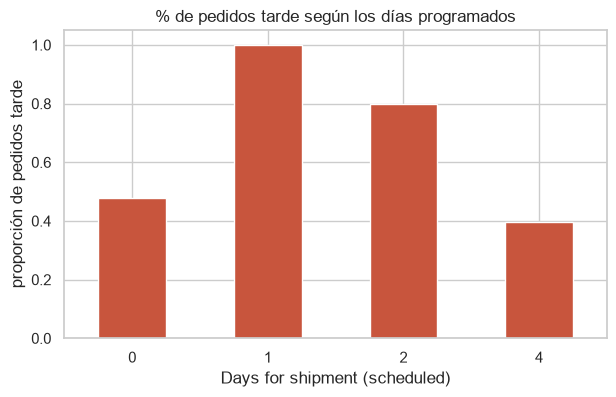

Days for shipment (scheduled)
0    0.479
1    1.000
2    0.798
4    0.398
Name: Late_delivery_risk, dtype: float64

In [14]:
VARIABLE_NUMERICA = "Days for shipment (scheduled)"

tasa_por_dias = df_limpio.groupby(VARIABLE_NUMERICA)[OBJETIVO].mean()

fig, ax = plt.subplots(figsize=(7, 4))
tasa_por_dias.plot.bar(ax=ax, color="#C8553D")
ax.set_ylabel("proporción de pedidos tarde")
ax.set_title("% de pedidos tarde según los días programados")
ax.tick_params(axis="x", rotation=0)
plt.show()
tasa_por_dias.round(3)

Cuando se prometen 1 día, el 100 % de los pedidos llega tarde; con 2 días, el 80 %; con 4 días, solo el 40 %. Prometer plazos cortos es la principal causa del retraso.

### 4.3 Una variable categórica frente al objetivo


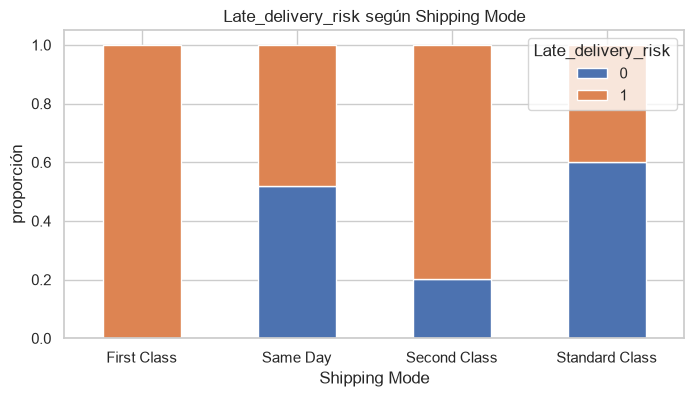

,pedidos,pct_tarde,dias_programados,dias_reales
Shipping Mode,,,,
First Class,26513,1.00,1.0,2.00
Second Class,33806,0.80,2.0,3.99
Same Day,9293,0.48,0.0,0.48
Standard Class,103153,0.40,4.0,3.99


In [15]:
VARIABLE_CATEGORICA = "Shipping Mode"

fig, ax = plt.subplots(figsize=(8, 4))
pd.crosstab(df_limpio[VARIABLE_CATEGORICA], df_limpio[OBJETIVO], normalize="index").plot.bar(stacked=True, ax=ax)
ax.set_ylabel("proporción")
ax.set_title(f"{OBJETIVO} según {VARIABLE_CATEGORICA}")
ax.tick_params(axis="x", rotation=0)
plt.show()

# Días prometidos frente a días reales por modo de envío
df_limpio.groupby(VARIABLE_CATEGORICA).agg(
    pedidos=(OBJETIVO, "size"),
    pct_tarde=(OBJETIVO, "mean"),
    dias_programados=("Days for shipment (scheduled)", "mean"),
    dias_reales=("Days for shipping (real)", "mean"),
).round(2).sort_values("pct_tarde", ascending=False)

First Class promete 1 día pero tarda 2: el 100 % de sus pedidos llega tarde. Second Class promete 2 y tarda 4 (80 % tarde). Standard Class promete 4 y en promedio cumple (40 % tarde). Como cada modo tiene un plazo fijo, el modo de envío y los días programados dicen casi lo mismo: en el modelo conviene usar solo uno de los dos.

### 4.4 Un KPI calculado con los datos

Los KPIs de la sección 1 se calculan casi siempre con `groupby`: **agrupar** por una columna y **resumir** otra. Ajusten la celda para calcular uno de sus KPIs (por ejemplo, la mediana del objetivo por categoría, o el total por mes).

In [16]:
# KPI 1: tasa de entregas a tiempo = pedidos a tiempo / pedidos enviados
tasa_a_tiempo = 1 - df_limpio[OBJETIVO].mean()
print(f"Tasa de entregas a tiempo (toda la empresa): {tasa_a_tiempo:.1%}")

display((1 - df_limpio.groupby("Market")[OBJETIVO].mean()).rename("tasa_a_tiempo").round(3).sort_values())
display((1 - df_limpio.groupby("Shipping Mode")[OBJETIVO].mean()).rename("tasa_a_tiempo").round(3).sort_values())

Tasa de entregas a tiempo (toda la empresa): 42.7%


Market
Europe          0.423
Pacific Asia    0.426
USCA            0.426
LATAM           0.431
Africa          0.432
Name: tasa_a_tiempo, dtype: float64

Shipping Mode
First Class       0.000
Second Class      0.202
Same Day          0.521
Standard Class    0.602
Name: tasa_a_tiempo, dtype: float64

In [17]:
# H2: ¿el mercado cambia el retraso? Comparamos dentro de cada modo de envío (peras con peras)
display(pd.crosstab(df_limpio["Shipping Mode"], df_limpio["Market"],
                    values=df_limpio[OBJETIVO], aggfunc="mean").round(3))

# H3: ¿las características del pedido cambian entre pedidos tarde y a tiempo?
display(df_limpio.groupby(OBJETIVO)[["Sales", "Order Item Quantity", "Order Item Discount Rate", "Product Price"]].mean().round(2))

Market,Africa,Europe,LATAM,Pacific Asia,USCA
Shipping Mode,,,,,
First Class,1.000,1.000,1.000,1.000,1.000
Same Day,0.464,0.488,0.504,0.454,0.464
Second Class,0.801,0.802,0.791,0.804,0.796
Standard Class,0.399,0.398,0.395,0.400,0.398


,Sales,Order Item Quantity,Order Item Discount Rate,Product Price
Late_delivery_risk,,,,
0,204.48,2.13,0.1,141.71
1,203.34,2.13,0.1,140.96


 Dentro de cada modo de envío, el retraso es casi igual en los 5 mercados (máximo 5 puntos de diferencia). Tampoco cambian el valor, la cantidad ni el descuento entre pedidos tarde y a tiempo. H2 y H3 se rechazan.

### 4.5 Hallazgos del EDA

| # | Hallazgo | Evidencia | Implicación | Hipótesis |
|---|---|---|---|---|
| 1 | El modo de envío es lo que más explica el retraso: First Class llega tarde el **100 %** de las veces, Second Class el 80 % y Standard Class el 40 %. | Gráfica y tabla de la sección 4.3 | El modo de envío debe entrar al modelo. El negocio debe revisar los plazos de First y Second Class. | **Confirma H1** |
| 2 | El problema es la promesa, no la lentitud: First Class promete 1 día y tarda 2; Second Class promete 2 y tarda 4. | Tabla de días programados y reales (4.3) | Modo de envío y días programados dicen lo mismo: usar solo uno en el modelo. Los días reales no se pueden usar (*data leakage*). | Amplía H1 |
| 3 | El mercado de destino y las características del pedido **no cambian** el retraso. | Tablas de la prueba de H2 y H3 | Estas variables probablemente aportarán poco al modelo. | **Rechaza H2 y H3** |

---
## 5. Modelo (28 de octubre)

El objetivo de esta sección **no** es encontrar el mejor modelo posible, sino responder dos preguntas:

1. ¿Nuestro modelo le gana a un ***baseline***, es decir, a una regla simple sin inteligencia?
2. ¿Cumple el **criterio de éxito** que definimos en la sección 1?

### 5.1 Variables del modelo

Si dejan `VARIABLES = []`, el notebook usa automáticamente las columnas numéricas y las categóricas con pocas categorías (hasta 15), sin el objetivo, sin identificadores y sin las columnas de `COLUMNAS_A_EXCLUIR`. **COMPLETAR (recomendado):** escriban la lista con las variables que el EDA mostró como importantes.

In [24]:
VARIABLES = [
    "Shipping Mode",             # H1: lo que más explica el retraso
    "Type",                      # tipo de pago
    "Market",                    # H2: mercado de destino
    "Customer Segment",          # tipo de cliente
    "Order Item Quantity",       # H3: características del pedido
    "Sales",
    "Order Item Discount Rate",
    "mes_pedido",                # fecha del pedido (creadas en la sección 3)
    "dia_semana_pedido",
]
if not VARIABLES:
    candidatas = df_limpio.columns.drop([OBJETIVO, *COLUMNAS_A_EXCLUIR], errors="ignore")
    VARIABLES = [
        c for c in candidatas
        if df_limpio[c].nunique() < len(df_limpio)  # descarta identificadores
        and (pd.api.types.is_numeric_dtype(df_limpio[c]) or df_limpio[c].nunique() <= 15)
    ]

X = df_limpio[VARIABLES]
y = df_limpio[OBJETIVO]
vars_numericas = X.select_dtypes(include="number").columns.tolist()
vars_categoricas = X.select_dtypes(exclude="number").columns.tolist()
print(f"{len(vars_numericas)} variables numéricas: {vars_numericas}")
print(f"{len(vars_categoricas)} variables categóricas: {vars_categoricas}")

5 variables numéricas: ['Order Item Quantity', 'Sales', 'Order Item Discount Rate', 'mes_pedido', 'dia_semana_pedido']
4 variables categóricas: ['Shipping Mode', 'Type', 'Market', 'Customer Segment']


### 5.2 Separar entrenamiento y prueba

El modelo **aprende** con el 80 % de los datos (*train*) y lo **evaluamos** con el 20 % restante (*test*), que nunca vio. Así medimos qué tan bien funcionará con datos nuevos, no qué tan bien memorizó.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA,
    stratify=y if TIPO_PROBLEMA == "clasificacion" else None,  # misma proporción de clases en train y test
)
print(f"Train: {len(X_train):,} filas · Test: {len(X_test):,} filas")

Train: 138,212 filas · Test: 34,553 filas


### 5.3 Preparar las variables automáticamente

Los modelos solo entienden números y no aceptan nulos. Este bloque prepara los datos **aprendiendo solo de train**, lo que evita la fuga de información (*data leakage*):

- **Numéricas:** rellena los nulos con la mediana y las pone en la misma escala.
- **Categóricas:** rellena los nulos con la categoría más frecuente y crea una columna 0/1 por categoría (*one-hot encoding*).

En la clase del 11 de noviembre veremos en detalle cómo funcionan estos `Pipeline`.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocesamiento = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), vars_numericas),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), vars_categoricas),
])

### 5.4 Entrenar el *baseline* y dos modelos

| Modelo | Regresión | Clasificación |
|---|---|---|
| ***Baseline*** | Predice siempre la **mediana** | Predice siempre la **clase más frecuente** |
| **Modelo lineal** | Regresión lineal | Regresión logística |
| **Árbol de decisión** | Árbol con profundidad máxima 5 | Árbol con profundidad máxima 5 |

Cada modelo se une a la preparación de la sección 5.3 con `make_pipeline`, se entrena con `fit` y predice con `predict`.

In [27]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, mean_absolute_error, mean_absolute_percentage_error,
    precision_score, r2_score, recall_score,
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

if TIPO_PROBLEMA == "regresion":
    modelos = {
        "Baseline (mediana)": DummyRegressor(strategy="median"),
        "Regresión lineal": LinearRegression(),
        "Árbol de decisión": DecisionTreeRegressor(max_depth=5, random_state=SEMILLA),
    }
else:
    modelos = {
        "Baseline (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
        "Regresión logística": LogisticRegression(max_iter=1000),
        "Árbol de decisión": DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
    }


def evaluar(y_real, y_pred):
    """Calcula las métricas del tipo de problema."""
    if TIPO_PROBLEMA == "regresion":
        return {
            "MAE": mean_absolute_error(y_real, y_pred),
            "MAPE (%)": mean_absolute_percentage_error(y_real, y_pred) * 100,
            "R2": r2_score(y_real, y_pred),
        }
    promedio = "binary" if y.nunique() == 2 else "macro"
    positiva = 1  # nos interesa detectar los pedidos que llegan TARDE (Late_delivery_risk = 1)
    opciones = {"average": promedio, "zero_division": 0}
    if promedio == "binary":
        opciones["pos_label"] = positiva
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, **opciones),
        "recall": recall_score(y_real, y_pred, **opciones),
        "F1": f1_score(y_real, y_pred, **opciones),
    }


entrenados, filas = {}, []
for nombre, modelo in modelos.items():
    pipe = make_pipeline(preprocesamiento, modelo).fit(X_train, y_train)
    entrenados[nombre] = pipe
    filas.append({"modelo": nombre, "conjunto": "train", **evaluar(y_train, pipe.predict(X_train))})
    filas.append({"modelo": nombre, "conjunto": "test", **evaluar(y_test, pipe.predict(X_test))})

resultados = (
    pd.DataFrame(filas)
    .pivot(index="modelo", columns="conjunto")
    .reindex(columns=["train", "test"], level=1)
    .reindex(list(modelos))
    .round(3)
)
resultados

accuracy        precision        recall         \
conjunto                          train   test     train   test  train   test   
modelo                                                                          
Baseline (clase más frecuente)    0.573  0.573     0.573  0.573  1.000  1.000   
Regresión logística               0.697  0.698     0.887  0.885  0.540  0.543   
Árbol de decisión                 0.699  0.699     0.874  0.870  0.554  0.557   

                                   F1         
conjunto                        train   test  
modelo                                        
Baseline (clase más frecuente)  0.728  0.728  
Regresión logística             0.671  0.673  
Árbol de decisión               0.678  0.679

**Cómo leer la tabla**

- **Regresión:** MAE y MAPE son errores (**más bajo es mejor**); MAE está en las unidades del objetivo y MAPE en porcentaje. R² va de 0 a 1 (**más alto es mejor**).
- **Clasificación:** todas las métricas van de 0 a 1 (**más alto es mejor**). Si las clases están desbalanceadas, miren **recall** y **F1**, no solo *accuracy*. En este proyecto, precision y recall se calculan para la clase 1 (pedido tarde)
- **Train frente a test:** si el modelo es mucho mejor en train que en test, está **memorizando** (*overfitting*).

> Si `MAPE` sale enorme, revisen si el objetivo tiene valores en cero o muy cercanos a cero: en ese caso usen MAE.

### 5.5 ¿En qué se equivoca el modelo?

Elijan el modelo con mejor resultado en **test** y escriban su nombre en `MEJOR_MODELO`.

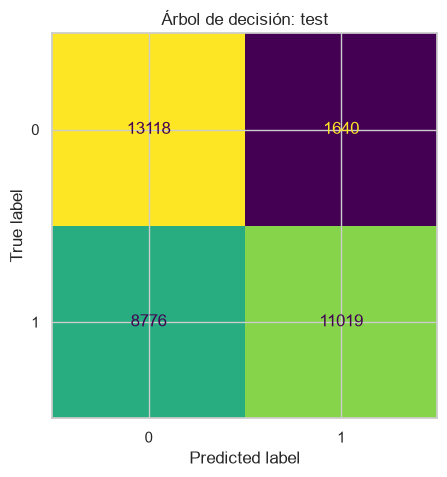

In [28]:
MEJOR_MODELO = "Árbol de decisión"  # mejor recall y F1 en test
mejor = entrenados[MEJOR_MODELO]
pred_test = mejor.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 5))
if TIPO_PROBLEMA == "regresion":
    ax.scatter(y_test, pred_test, alpha=0.4)
    limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
    ax.plot(limites, limites, color="red", linestyle="--", label="predicción perfecta")
    ax.set_xlabel("valor real")
    ax.set_ylabel("valor predicho")
    ax.legend()
else:
    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ax, colorbar=False)
ax.set_title(f"{MEJOR_MODELO}: test")
plt.show()

In [29]:
# Pedidos que de verdad llegaron tarde: ¿cuántos detectó el modelo en cada modo de envío?
errores = X_test.assign(real=y_test, predicho=pred_test)
tardios = errores[errores["real"] == 1]

tabla_errores = tardios.groupby("Shipping Mode")["predicho"].agg(tardios="count", detectados="sum")
tabla_errores["se_escapan"] = tabla_errores["tardios"] - tabla_errores["detectados"]
tabla_errores["recall"] = (tabla_errores["detectados"] / tabla_errores["tardios"]).round(2)
tabla_errores

,tardios,detectados,se_escapan,recall
Shipping Mode,,,,
First Class,5282,5282,0,1.00
Same Day,920,269,651,0.29
Second Class,5468,5468,0,1.00
Standard Class,8125,0,8125,0.00


**Interpretación del modelo**

| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo elegí y por qué? | El **árbol de decisión**. Empata con la regresión logística, pero tiene un poco más de recall en test (0,557 frente a 0,543), que es la métrica que más importa: que no se escapen pedidos tardíos. Además, sus reglas son fáciles de explicar. |
| ¿Cuánto mejora frente al *baseline*? | El baseline marca todos los pedidos como tardíos: recall 1,0 pero precisión de solo 0,573, así que no ayuda a priorizar. El árbol sube la precisión a **0,870** (de cada 100 pedidos que marca, 87 sí llegan tarde) y el accuracy de 0,573 a **0,699**. |
| ¿Cumple el criterio de éxito de la sección 1? | **No.** El recall en test es 0,557 y la meta era 0,80. El modelo detecta 56 de cada 100 pedidos tardíos. |
| ¿Hay *overfitting*? | No. Train y test dan casi lo mismo (accuracy 0,699 en ambos), así que el modelo no está memorizando. |
| ¿En qué casos se equivoca más? | En **Standard Class**: no detecta ninguno de sus 8.125 pedidos tardíos. En First y Second Class detecta el 100 %. El modelo aprendió casi una sola regla: "First o Second Class → tarde; Standard → a tiempo". Con las variables del dataset no se puede saber cuáles pedidos de Standard Class se van a retrasar. |

---
## 6. Conclusiones (11 de noviembre)

### 6.1 Guardar el modelo

`joblib` guarda en un archivo el pipeline completo (preparación + modelo), listo para usarse sin volver a entrenar. La carpeta `models/` está en `.gitignore`: el modelo se regenera ejecutando el notebook.

In [23]:
import joblib

Path("../models").mkdir(parents=True, exist_ok=True)
joblib.dump(mejor, "../models/modelo.joblib")
print("Modelo guardado en models/modelo.joblib")

# Comprobación: cargarlo y predecir las primeras 3 filas de test
modelo_cargado = joblib.load("../models/modelo.joblib")
print(pd.DataFrame({"real": y_test.head(3).to_numpy(), "predicho": modelo_cargado.predict(X_test.head(3))}))

Modelo guardado en models/modelo.joblib
   real  predicho
0     0         0
1     0         0
2     0         0


### 6.2 Conclusiones para el negocio

**COMPLETAR.** Escríbanlas pensando en la persona que toma la decisión, no en un público técnico. Son la base de las diapositivas finales.

1. **Respuesta al problema:** ¿qué puede hacer ahora el negocio que antes no podía?
2. **Resultado principal:** en una frase y en unidades de negocio (por ejemplo, "el avalúo se equivoca en promedio un 11 %").
3. **Límites:** ¿cuándo **no** conviene confiar en el modelo? (rangos de valores, grupos con pocos datos, periodos).
4. **Siguientes pasos:** ¿qué harían con un mes más? (más datos, otras variables, otros modelos, una API o un dashboard).